In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (
    KFold, StratifiedKFold, RepeatedStratifiedKFold, LeaveOneOut,
    cross_val_score
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, matthews_corrcoef, cohen_kappa_score
)

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'
print("Cross-validation and statistical evaluation modules loaded successfully.")

Cross-validation and statistical evaluation modules loaded successfully.


In [2]:
csv_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(csv_path):
    csv_path = os.path.join("27-10-2026", "Task 2", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(csv_path)
print(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")

num_features = [
    'Age', 'Rating', 'Positive Feedback Count', 'Review_Length',
    'Review_Word_Count', 'Exclamation_Count', 'Sentiment_Compound',
    'Sentiment_Pos', 'Sentiment_Neg', 'Positive_Word_Count',
    'Negative_Word_Count', 'Fit_Issue_Word_Count', 'Rating_x_Sentiment'
]
cat_features = ['Department Name', 'Division Name']
target = 'Recommended IND'

X = df[num_features + cat_features]
y = df[target]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
    ]
)

X_trans = preprocessor.fit_transform(X)
print(f"Dataset preprocessed: {X_trans.shape[0]} observations across {X_trans.shape[1]} features.")

Loaded dataset: 23486 rows, 23 columns
Dataset preprocessed: 23486 observations across 20 features.


In [3]:
eval_model = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.05, max_depth=5, subsample=0.8, random_state=42
)

cv_schemes = {
    'Stratified 5-Fold': StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    'Stratified 10-Fold': StratifiedKFold(n_splits=10, shuffle=True, random_state=42),
    'Standard (Unstratified) 5-Fold': KFold(n_splits=5, shuffle=True, random_state=42),
    'Repeated Stratified 5-Fold (3x)': RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
}

strategy_summary = []
fold_detailed_records = []

for scheme_name, cv_splitter in cv_schemes.items():
    t0 = time.time()
    fold_idx = 1
    
    acc_scores, rec0_scores, f1_macro_scores, roc_auc_scores, mcc_scores = [], [], [], [], []
    
    for train_idx, test_idx in cv_splitter.split(X_trans, y):
        X_tr, X_te = X_trans[train_idx], X_trans[test_idx]
        y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]
        
        eval_model.fit(X_tr, y_tr)
        preds = eval_model.predict(X_te)
        probs = eval_model.predict_proba(X_te)[:, 1]
        
        acc = accuracy_score(y_te, preds)
        rec0 = recall_score(y_te, preds, pos_label=0)
        f1_m = f1_score(y_te, preds, average='macro')
        auc = roc_auc_score(y_te, probs)
        mcc = matthews_corrcoef(y_te, preds)
        
        acc_scores.append(acc)
        rec0_scores.append(rec0)
        f1_macro_scores.append(f1_m)
        roc_auc_scores.append(auc)
        mcc_scores.append(mcc)
        
        fold_detailed_records.append({
            'CV_Scheme': scheme_name,
            'Fold': fold_idx,
            'Accuracy': acc,
            'Recall_Class0': rec0,
            'Macro_F1': f1_m,
            'ROC_AUC': auc,
            'MCC': mcc
        })
        fold_idx += 1
        
    duration = time.time() - t0
    k_splits = len(acc_scores)
    
    strategy_summary.append({
        'CV_Scheme': scheme_name,
        'Num_Splits': k_splits,
        'Runtime_Seconds': round(duration, 2),
        'Mean_Accuracy': round(np.mean(acc_scores), 4),
        'Std_Accuracy': round(np.std(acc_scores), 4),
        'CI95_Accuracy': f"[{np.mean(acc_scores) - 1.96*np.std(acc_scores)/np.sqrt(k_splits):.4f}, {np.mean(acc_scores) + 1.96*np.std(acc_scores)/np.sqrt(k_splits):.4f}]",
        'Mean_Macro_F1': round(np.mean(f1_macro_scores), 4),
        'Std_Macro_F1': round(np.std(f1_macro_scores), 4),
        'Mean_ROC_AUC': round(np.mean(roc_auc_scores), 4),
        'Std_ROC_AUC': round(np.std(roc_auc_scores), 4),
        'Mean_MCC': round(np.mean(mcc_scores), 4),
        'Std_MCC': round(np.std(mcc_scores), 4)
    })

df_strategy = pd.DataFrame(strategy_summary)
df_strategy.to_csv("cross_validation_strategies_benchmark.csv", index=False)

df_folds = pd.DataFrame(fold_detailed_records)
df_folds.to_csv("fold_by_fold_stability_metrics.csv", index=False)
df_strategy

,CV_Scheme,Num_Splits,Runtime_Seconds,Mean_Accuracy,Std_Accuracy,CI95_Accuracy,Mean_Macro_F1,Std_Macro_F1,Mean_ROC_AUC,Std_ROC_AUC,Mean_MCC,Std_MCC
0,Stratified 5-Fold,5,20.90,0.9405,0.0034,"[0.9376, 0.9435]",0.9005,0.0054,0.9788,0.0010,0.8017,0.0108
1,Stratified 10-Fold,10,47.27,0.9405,0.0039,"[0.9381, 0.9430]",0.9007,0.0062,0.9788,0.0009,0.8021,0.0123
2,Standard (Unstratified) 5-Fold,5,20.74,0.9413,0.0018,"[0.9398, 0.9429]",0.9015,0.0029,0.9791,0.0015,0.8035,0.0059
3,Repeated Stratified 5-Fold (3x),15,62.66,0.9414,0.0037,"[0.9395, 0.9432]",0.9020,0.0059,0.9790,0.0012,0.8046,0.0117


C:\Users\panch\AppData\Local\Temp\ipykernel_11900\3325657668.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_box, x='CV_Scheme', y='Macro_F1', palette='Blues', ax=axes[0])
C:\Users\panch\AppData\Local\Temp\ipykernel_11900\3325657668.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_box, x='CV_Scheme', y='MCC', palette='Greens', ax=axes[1])


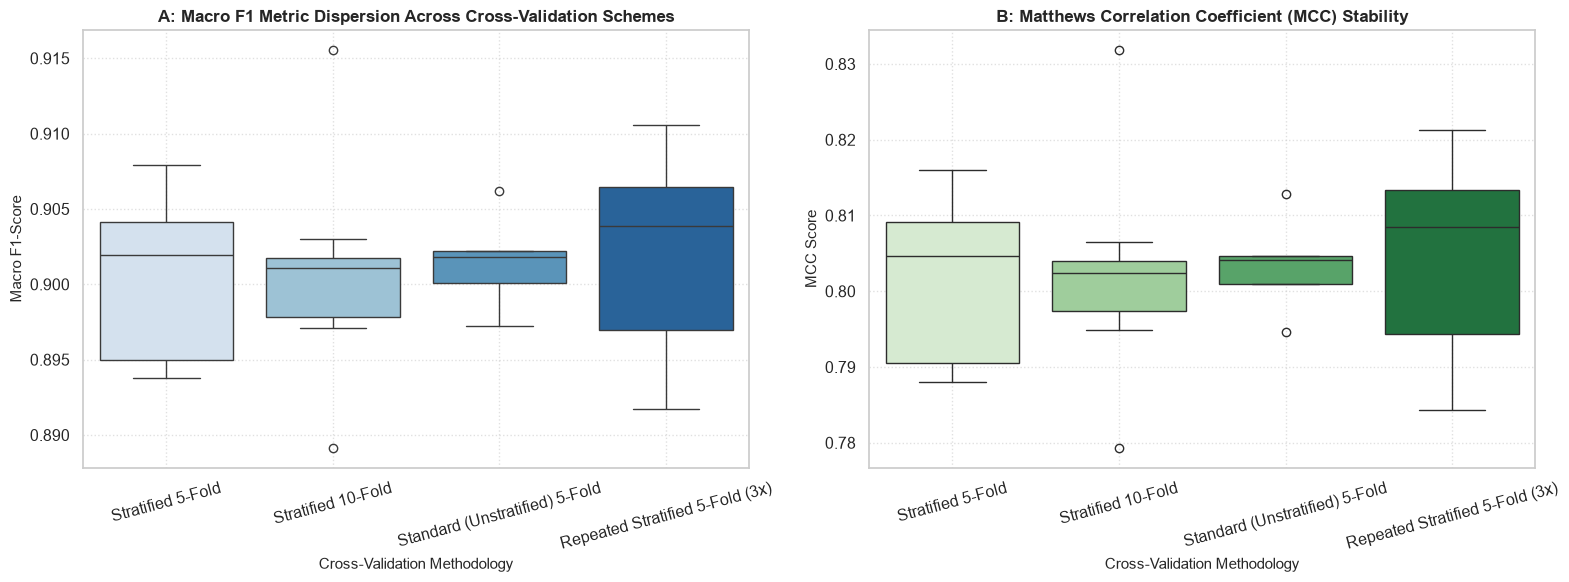

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

df_box = df_folds[df_folds['CV_Scheme'].isin(['Stratified 5-Fold', 'Stratified 10-Fold', 'Standard (Unstratified) 5-Fold', 'Repeated Stratified 5-Fold (3x)'])]
sns.boxplot(data=df_box, x='CV_Scheme', y='Macro_F1', palette='Blues', ax=axes[0])
axes[0].set_title("A: Macro F1 Metric Dispersion Across Cross-Validation Schemes", fontweight='bold', fontsize=12)
axes[0].set_ylabel("Macro F1-Score", fontsize=11)
axes[0].set_xlabel("Cross-Validation Methodology", fontsize=11)
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(True, linestyle=':', alpha=0.6)

sns.boxplot(data=df_box, x='CV_Scheme', y='MCC', palette='Greens', ax=axes[1])
axes[1].set_title("B: Matthews Correlation Coefficient (MCC) Stability", fontweight='bold', fontsize=12)
axes[1].set_ylabel("MCC Score", fontsize=11)
axes[1].set_xlabel("Cross-Validation Methodology", fontsize=11)
axes[1].tick_params(axis='x', rotation=15)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("cross_validation_fold_stability_boxplots.png", dpi=300)
plt.show()

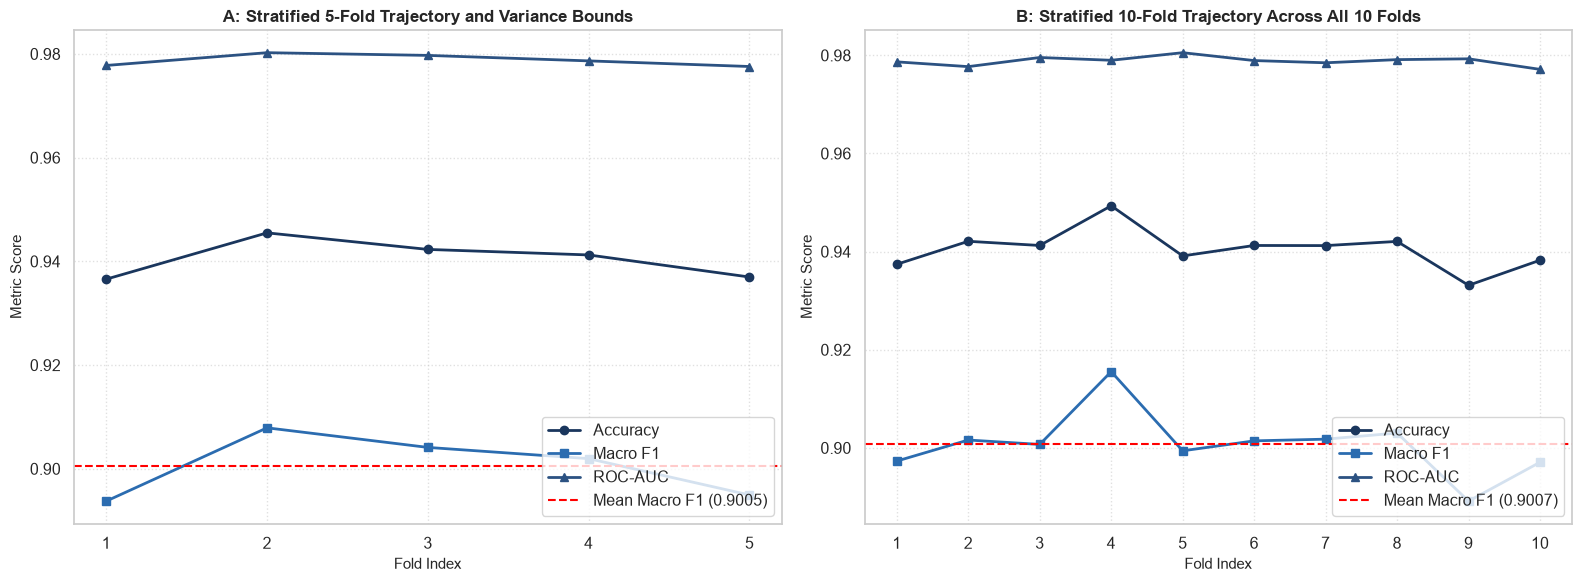

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

df_5fold = df_folds[df_folds['CV_Scheme'] == 'Stratified 5-Fold']
axes[0].plot(df_5fold['Fold'], df_5fold['Accuracy'], marker='o', linewidth=2, color='#1A365D', label='Accuracy')
axes[0].plot(df_5fold['Fold'], df_5fold['Macro_F1'], marker='s', linewidth=2, color='#2B6CB0', label='Macro F1')
axes[0].plot(df_5fold['Fold'], df_5fold['ROC_AUC'], marker='^', linewidth=2, color='#2C5282', label='ROC-AUC')
axes[0].axhline(df_5fold['Macro_F1'].mean(), color='red', linestyle='--', label=f'Mean Macro F1 ({df_5fold["Macro_F1"].mean():.4f})')
axes[0].set_title("A: Stratified 5-Fold Trajectory and Variance Bounds", fontweight='bold', fontsize=12)
axes[0].set_xlabel("Fold Index", fontsize=11)
axes[0].set_ylabel("Metric Score", fontsize=11)
axes[0].set_xticks(df_5fold['Fold'])
axes[0].legend(loc='lower right', frameon=True)
axes[0].grid(True, linestyle=':', alpha=0.6)

df_10fold = df_folds[df_folds['CV_Scheme'] == 'Stratified 10-Fold']
axes[1].plot(df_10fold['Fold'], df_10fold['Accuracy'], marker='o', linewidth=2, color='#1A365D', label='Accuracy')
axes[1].plot(df_10fold['Fold'], df_10fold['Macro_F1'], marker='s', linewidth=2, color='#2B6CB0', label='Macro F1')
axes[1].plot(df_10fold['Fold'], df_10fold['ROC_AUC'], marker='^', linewidth=2, color='#2C5282', label='ROC-AUC')
axes[1].axhline(df_10fold['Macro_F1'].mean(), color='red', linestyle='--', label=f'Mean Macro F1 ({df_10fold["Macro_F1"].mean():.4f})')
axes[1].set_title("B: Stratified 10-Fold Trajectory Across All 10 Folds", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Fold Index", fontsize=11)
axes[1].set_ylabel("Metric Score", fontsize=11)
axes[1].set_xticks(df_10fold['Fold'])
axes[1].legend(loc='lower right', frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("fold_performance_variance_curves.png", dpi=300)
plt.show()

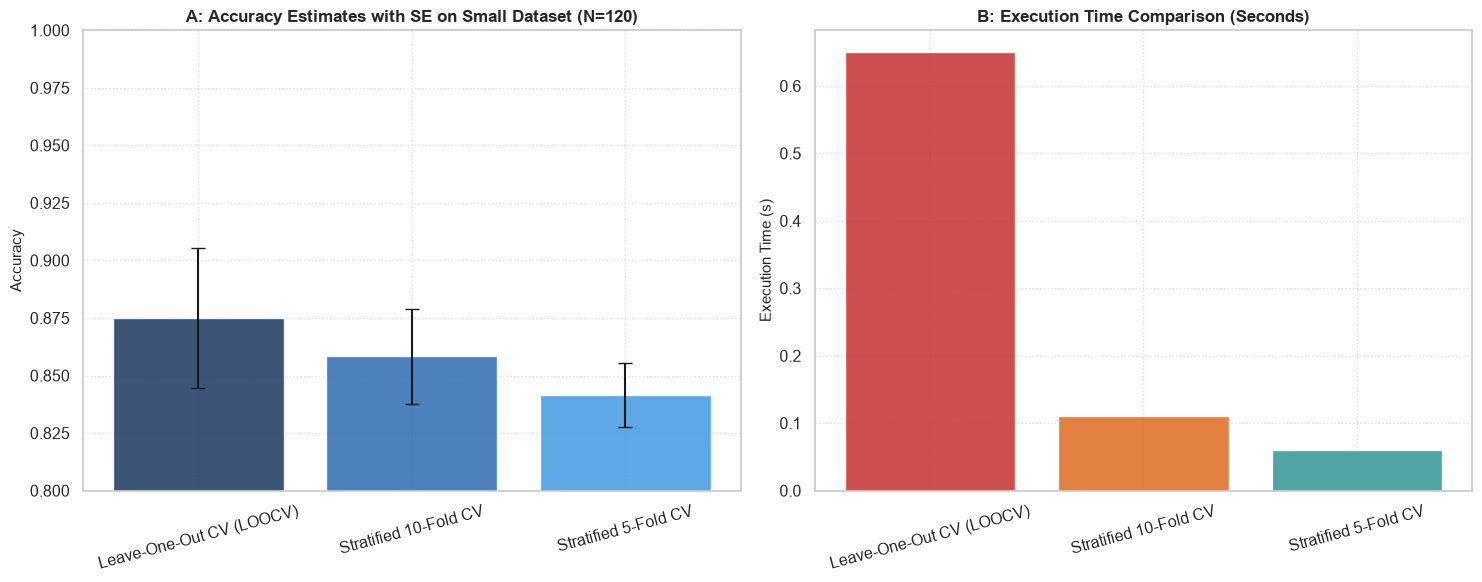

In [6]:
df_small = df.sample(n=120, random_state=42)
X_small_trans = preprocessor.transform(df_small[num_features + cat_features])
y_small = df_small[target].values

loo = LeaveOneOut()
lr_small = LogisticRegression(max_iter=1000, random_state=42)

t0 = time.time()
loo_preds = []
for train_idx, test_idx in loo.split(X_small_trans):
    X_tr_s, X_te_s = X_small_trans[train_idx], X_small_trans[test_idx]
    y_tr_s, y_te_s = y_small[train_idx], y_small[test_idx]
    lr_small.fit(X_tr_s, y_tr_s)
    loo_preds.append(lr_small.predict(X_te_s)[0])
loo_time = time.time() - t0

loo_acc = accuracy_score(y_small, loo_preds)
loo_f1 = f1_score(y_small, loo_preds, average='macro')

skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
t0 = time.time()
skf5_acc = cross_val_score(lr_small, X_small_trans, y_small, cv=skf5, scoring='accuracy')
skf5_f1 = cross_val_score(lr_small, X_small_trans, y_small, cv=skf5, scoring='f1_macro')
skf5_time = time.time() - t0

skf10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
t0 = time.time()
skf10_acc = cross_val_score(lr_small, X_small_trans, y_small, cv=skf10, scoring='accuracy')
skf10_f1 = cross_val_score(lr_small, X_small_trans, y_small, cv=skf10, scoring='f1_macro')
skf10_time = time.time() - t0

df_loocv_comp = pd.DataFrame([
    {
        'CV_Method': 'Leave-One-Out CV (LOOCV)',
        'Sample_Size (N)': len(y_small),
        'Num_Models_Fitted': len(y_small),
        'Compute_Time_Seconds': round(loo_time, 2),
        'Mean_Accuracy': round(loo_acc, 4),
        'Accuracy_SE': round(np.sqrt(loo_acc * (1 - loo_acc) / len(y_small)), 4),
        'Mean_Macro_F1': round(loo_f1, 4),
        'Evaluation_Bias': 'Virtually Unbiased (N-1 train size)'
    },
    {
        'CV_Method': 'Stratified 10-Fold CV',
        'Sample_Size (N)': len(y_small),
        'Num_Models_Fitted': 10,
        'Compute_Time_Seconds': round(skf10_time, 2),
        'Mean_Accuracy': round(np.mean(skf10_acc), 4),
        'Accuracy_SE': round(np.std(skf10_acc) / np.sqrt(10), 4),
        'Mean_Macro_F1': round(np.mean(skf10_f1), 4),
        'Evaluation_Bias': 'Low (0.9N train size)'
    },
    {
        'CV_Method': 'Stratified 5-Fold CV',
        'Sample_Size (N)': len(y_small),
        'Num_Models_Fitted': 5,
        'Compute_Time_Seconds': round(skf5_time, 2),
        'Mean_Accuracy': round(np.mean(skf5_acc), 4),
        'Accuracy_SE': round(np.std(skf5_acc) / np.sqrt(5), 4),
        'Mean_Macro_F1': round(np.mean(skf5_f1), 4),
        'Evaluation_Bias': 'Slight Pessimistic Bias (0.8N train size)'
    }
])
df_loocv_comp.to_csv("loocv_small_sample_comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
methods = df_loocv_comp['CV_Method']
axes[0].bar(methods, df_loocv_comp['Mean_Accuracy'], yerr=df_loocv_comp['Accuracy_SE'], capsize=5, color=['#1A365D', '#2B6CB0', '#4299E1'], alpha=0.85)
axes[0].set_title("A: Accuracy Estimates with SE on Small Dataset (N=120)", fontweight='bold', fontsize=12)
axes[0].set_ylabel("Accuracy", fontsize=11)
axes[0].set_ylim(0.80, 1.0)
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].bar(methods, df_loocv_comp['Compute_Time_Seconds'], color=['#C53030', '#DD6B20', '#319795'], alpha=0.85)
axes[1].set_title("B: Execution Time Comparison (Seconds)", fontweight='bold', fontsize=12)
axes[1].set_ylabel("Execution Time (s)", fontsize=11)
axes[1].tick_params(axis='x', rotation=15)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("loocv_vs_kfold_small_sample_tradeoff.png", dpi=300)
plt.show()